In [51]:
import pandas as pd

In [52]:
def freight_loading():
    csv_path="data/december_chart_inputs.csv"
    return pd.read_csv(csv_path)

In [53]:
freight=freight_loading()
freight.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,predicted_rate
0,TR-000001,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,360,Dry Van,32000,01-12-2025,NaN,NaN,NaN
1,TR-000002,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,360,Dry Van,32000,02-12-2025,NaN,NaN,NaN
2,TR-000003,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,360,Dry Van,32000,03-12-2025,NaN,NaN,NaN
3,TR-000004,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,360,Dry Van,32000,04-12-2025,NaN,NaN,NaN
4,TR-000005,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,360,Dry Van,32000,05-12-2025,NaN,NaN,NaN


## Understanding missing data and data types

In [54]:
freight.info()

<class 'pandas.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   load_id         31 non-null     str    
 1   pickup          31 non-null     str    
 2   delivery        31 non-null     str    
 3   pickup_lat      31 non-null     float64
 4   pickup_lon      31 non-null     float64
 5   delivery_lat    31 non-null     float64
 6   delivery_lon    31 non-null     float64
 7   distance        31 non-null     int64  
 8   equipment       31 non-null     str    
 9   weight          31 non-null     int64  
 10  date            31 non-null     str    
 11  market_index    0 non-null      float64
 12  quote_signal    0 non-null      float64
 13  predicted_rate  0 non-null      float64
dtypes: float64(7), int64(2), str(5)
memory usage: 3.5 KB


## Exploring data deeply to understand its distribution

In [55]:
%matplotlib inline

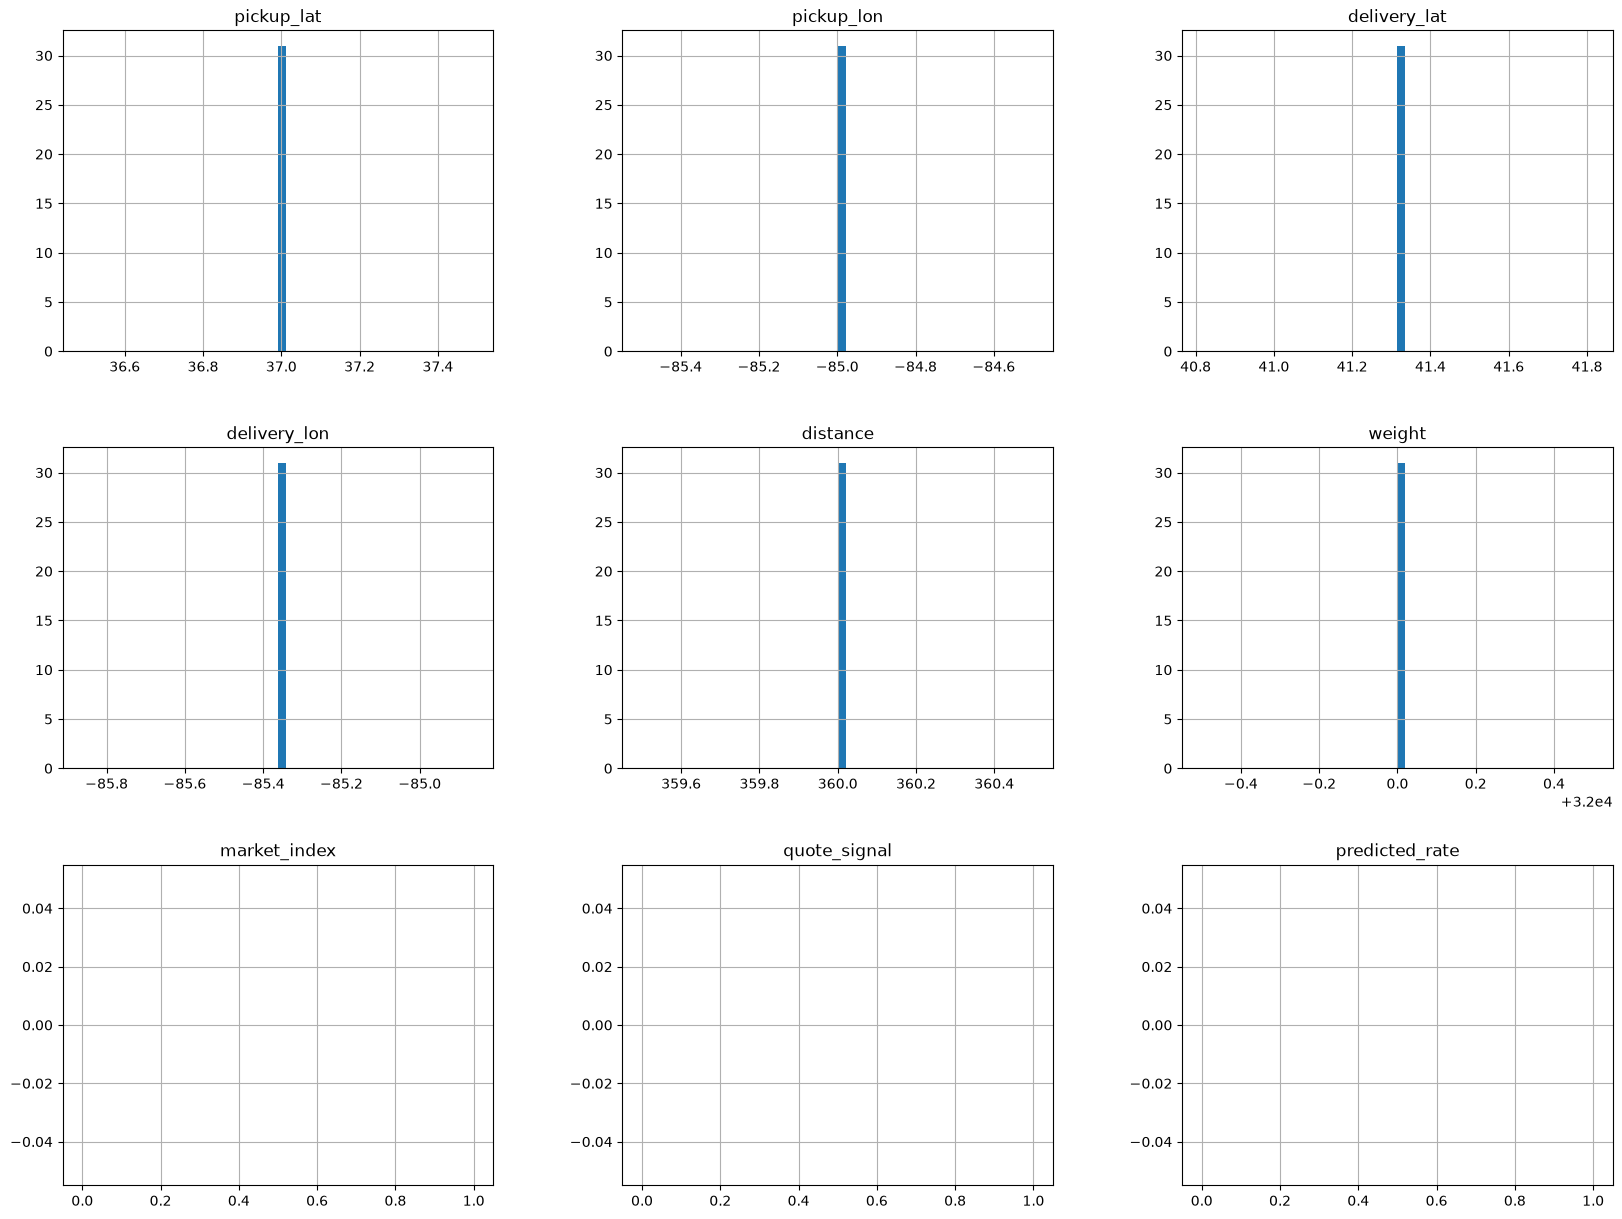

In [56]:
import matplotlib.pyplot as plt
freight.hist(bins=50,figsize=(20,15))
plt.show()

## Transforming date into machine readable format

In [57]:
date = freight["date"]
freight["date"] = pd.to_datetime(freight["date"], format="%d-%m-%Y")
freight["month"] = freight["date"].dt.month
freight["day"] = freight["date"].dt.day
freight["weekday"] = freight["date"].dt.weekday
freight["week_of_year"] = freight["date"].dt.isocalendar().week
freight["day_of_year"] = freight["date"].dt.dayofyear

In [59]:
freight.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,predicted_rate,month,day,weekday,week_of_year,day_of_year
0,TR-000001,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,360,Dry Van,32000,2025-12-01,NaN,NaN,NaN,12,1,0,49,335
1,TR-000002,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,360,Dry Van,32000,2025-12-02,NaN,NaN,NaN,12,2,1,49,336
2,TR-000003,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,360,Dry Van,32000,2025-12-03,NaN,NaN,NaN,12,3,2,49,337
3,TR-000004,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,360,Dry Van,32000,2025-12-04,NaN,NaN,NaN,12,4,3,49,338
4,TR-000005,Lexington,Fort Wayne,36.99152,-84.99876,41.31561,-85.36206,360,Dry Van,32000,2025-12-05,NaN,NaN,NaN,12,5,4,49,339


## Drop original date column and invalid negative "weight" rows

In [60]:
freight.drop(columns=["date"], inplace=True)
freight = freight[freight["weight"] >= 0].reset_index(drop=True)

In [61]:
freight.info()

<class 'pandas.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   load_id         31 non-null     str    
 1   pickup          31 non-null     str    
 2   delivery        31 non-null     str    
 3   pickup_lat      31 non-null     float64
 4   pickup_lon      31 non-null     float64
 5   delivery_lat    31 non-null     float64
 6   delivery_lon    31 non-null     float64
 7   distance        31 non-null     int64  
 8   equipment       31 non-null     str    
 9   weight          31 non-null     int64  
 10  market_index    0 non-null      float64
 11  quote_signal    0 non-null      float64
 12  predicted_rate  0 non-null      float64
 13  month           31 non-null     int32  
 14  day             31 non-null     int32  
 15  weekday         31 non-null     int32  
 16  week_of_year    31 non-null     UInt32 
 17  day_of_year     31 non-null     int32  
dtypes: 

In [62]:
import pandas as pd
import numpy as np

freight["distance_cat"] = pd.cut(
    freight["distance"],
    bins=[0, 250, 500, 750, 1000, 1500, np.inf],
    labels=[1, 2, 3, 4, 5, 6]
)

In [63]:
freight["distance_cat"].value_counts().sort_index()

distance_cat
1     0
2    31
3     0
4     0
5     0
6     0
Name: count, dtype: int64

In [64]:
freight.iloc[2]

load_id            TR-000003
pickup             Lexington
delivery          Fort Wayne
pickup_lat          36.99152
pickup_lon         -84.99876
delivery_lat        41.31561
delivery_lon       -85.36206
distance                 360
equipment            Dry Van
weight                 32000
market_index             NaN
quote_signal             NaN
predicted_rate           NaN
month                     12
day                        3
weekday                    2
week_of_year              49
day_of_year              337
distance_cat               2
Name: 2, dtype: object

## Load SimpleImputer to fill missing values

## Before Imputing [We have to drop text features and reinclude them using 1 hot encoder] also remove distance_cat 

In [65]:
freight_num = freight.drop(
    columns=["pickup", "delivery", "equipment", "load_id","distance_cat","predicted_rate"]
)
freight_num_dropped = freight[["equipment"]].copy()
load_id = freight["load_id"].copy()

In [66]:
import joblib
imputer = joblib.load("imputer.pkl")

In [67]:
freight_num.info()

<class 'pandas.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   pickup_lat    31 non-null     float64
 1   pickup_lon    31 non-null     float64
 2   delivery_lat  31 non-null     float64
 3   delivery_lon  31 non-null     float64
 4   distance      31 non-null     int64  
 5   weight        31 non-null     int64  
 6   market_index  0 non-null      float64
 7   quote_signal  0 non-null      float64
 8   month         31 non-null     int32  
 9   day           31 non-null     int32  
 10  weekday       31 non-null     int32  
 11  week_of_year  31 non-null     UInt32 
 12  day_of_year   31 non-null     int32  
dtypes: UInt32(1), float64(6), int32(4), int64(2)
memory usage: 2.7 KB


In [68]:
freight_num_imputed = pd.DataFrame(
    imputer.transform(freight_num),
    columns=freight_num.columns,
    index=freight_num.index
)

print(freight_num_imputed.head())

   pickup_lat  pickup_lon  delivery_lat  delivery_lon  distance   weight  \
0    36.99152   -84.99876      41.31561     -85.36206     360.0  32000.0   
1    36.99152   -84.99876      41.31561     -85.36206     360.0  32000.0   
2    36.99152   -84.99876      41.31561     -85.36206     360.0  32000.0   
3    36.99152   -84.99876      41.31561     -85.36206     360.0  32000.0   
4    36.99152   -84.99876      41.31561     -85.36206     360.0  32000.0   

   market_index  quote_signal  month  day  weekday  week_of_year  day_of_year  
0       1.05583      2.056935   12.0  1.0      0.0          49.0        335.0  
1       1.05583      2.056935   12.0  2.0      1.0          49.0        336.0  
2       1.05583      2.056935   12.0  3.0      2.0          49.0        337.0  
3       1.05583      2.056935   12.0  4.0      3.0          49.0        338.0  
4       1.05583      2.056935   12.0  5.0      4.0          49.0        339.0  


In [69]:
freight_num_imputed.head()

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,market_index,quote_signal,month,day,weekday,week_of_year,day_of_year
0,36.99152,-84.99876,41.31561,-85.36206,360.0,32000.0,1.05583,2.056935,12.0,1.0,0.0,49.0,335.0
1,36.99152,-84.99876,41.31561,-85.36206,360.0,32000.0,1.05583,2.056935,12.0,2.0,1.0,49.0,336.0
2,36.99152,-84.99876,41.31561,-85.36206,360.0,32000.0,1.05583,2.056935,12.0,3.0,2.0,49.0,337.0
3,36.99152,-84.99876,41.31561,-85.36206,360.0,32000.0,1.05583,2.056935,12.0,4.0,3.0,49.0,338.0
4,36.99152,-84.99876,41.31561,-85.36206,360.0,32000.0,1.05583,2.056935,12.0,5.0,4.0,49.0,339.0


## Load encoder and perform encoding on equipment

In [70]:
# Load encoder
encoder = joblib.load("onehot_encoder.pkl")

# Transform equipment column
encoded_equipment = encoder.transform(
    freight_num_dropped[["equipment"]]
)

# Convert to DataFrame
encoded_equipment_df = pd.DataFrame(
    encoded_equipment,
    columns=encoder.get_feature_names_out(["equipment"]),
    index=freight_num_dropped.index
)

print(encoded_equipment_df.head())

   equipment_Dry Van  equipment_Flatbed  equipment_Reefer
0                1.0                0.0               0.0
1                1.0                0.0               0.0
2                1.0                0.0               0.0
3                1.0                0.0               0.0
4                1.0                0.0               0.0


In [71]:
Final_1hot = pd.concat(
    [freight_num_imputed, encoded_equipment_df],
    axis=1
)

In [72]:
Final_1hot.loc[2]

pickup_lat              36.991520
pickup_lon             -84.998760
delivery_lat            41.315610
delivery_lon           -85.362060
distance               360.000000
weight               32000.000000
market_index             1.055830
quote_signal             2.056935
month                   12.000000
day                      3.000000
weekday                  2.000000
week_of_year            49.000000
day_of_year            337.000000
equipment_Dry Van        1.000000
equipment_Flatbed        0.000000
equipment_Reefer         0.000000
Name: 2, dtype: float64

## Missing Values fixed

In [73]:
Final_1hot.info()

<class 'pandas.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pickup_lat         31 non-null     float64
 1   pickup_lon         31 non-null     float64
 2   delivery_lat       31 non-null     float64
 3   delivery_lon       31 non-null     float64
 4   distance           31 non-null     float64
 5   weight             31 non-null     float64
 6   market_index       31 non-null     float64
 7   quote_signal       31 non-null     float64
 8   month              31 non-null     float64
 9   day                31 non-null     float64
 10  weekday            31 non-null     float64
 11  week_of_year       31 non-null     float64
 12  day_of_year        31 non-null     float64
 13  equipment_Dry Van  31 non-null     float64
 14  equipment_Flatbed  31 non-null     float64
 15  equipment_Reefer   31 non-null     float64
dtypes: float64(16)
memory usage: 4.0 KB


## Load XGBoost trained model and perform prediction

In [74]:
import joblib
model = joblib.load("best_xgboost_model.pkl")

In [75]:
y_pred_loaded = model.predict(Final_1hot)

In [76]:
import pandas as pd

# Create results dataframe
results = pd.DataFrame({
    "load_id": load_id,
    "date" : date,
    "Predicted_Posted_Rate": y_pred_loaded
    
})

# Sort by load_id
results = results.sort_values(by="load_id").reset_index(drop=True)

# Save to CSV
results.to_csv("December_Prediction.csv", index=False)

print(results.head())
print("\nCSV saved successfully as 'December_Prediction.csv'")

     load_id        date  Predicted_Posted_Rate
0  TR-000001  01-12-2025             871.600342
1  TR-000002  02-12-2025             871.600342
2  TR-000003  03-12-2025             872.686096
3  TR-000004  04-12-2025             873.277588
4  TR-000005  05-12-2025             857.759033

CSV saved successfully as 'December_Prediction.csv'
